In [2]:
import illustris_python as il
import numpy as np
import matplotlib.pylab as plt
import os
import h5py
from scipy.stats import binned_statistic
from scipy.stats import binned_statistic_2d
from scipy.interpolate import interp1d
from matplotlib.colors import LogNorm
from numpy import linalg as LA 

# Paths to the IllustrisTNG catalogues

basePath_TNG50 = '/home/tnguser/sims.TNG/TNG50-1/output/'

#SubhaloIDs = 117269 #Subhalo ID

#snapshot and redshift we will use
snap = 99
red = 0.0
h = 0.6774

In [3]:
# Subhalo properties we will read. For a full list, see: https://www.tng-project.org/data/docs/specifications/
fields_sub = ['SubhaloMassType','SubhaloMassInHalfRadType','SubhaloStarMetallicity',
             'SubhaloStellarPhotometrics','SubhaloSFR','SubhaloGrNr']
fields_halo = ['Group_M_Crit200','GroupFirstSub','GroupPos']

# Read subhalo properties

subhalos_TNG50 = il.groupcat.loadSubhalos(basePath_TNG50, snap, fields=fields_sub)
halos_TNG50 = il.groupcat.loadHalos(basePath_TNG50, snap, fields=fields_halo)

In [4]:
HaloMass = halos_TNG50['Group_M_Crit200']*10**10. / h

HaloID = subhalos_TNG50['SubhaloGrNr']

In [5]:
Mstarsubhalos_TNG50 = subhalos_TNG50['SubhaloMassType'][:,4]*10**10. /h  #Star

In [6]:
Mgassubhalos_TNG50 = subhalos_TNG50['SubhaloMassType'][:,0]*10**10/h
SubhaloSFR_TNG50 = subhalos_TNG50['SubhaloSFR']
#StarsCoords = stars['Coordinates']


sSFR = SubhaloSFR_TNG50/Mstarsubhalos_TNG50
SFE = SubhaloSFR_TNG50 /  Mgassubhalos_TNG50

/tmp/ipykernel_266/1543584093.py:6: RuntimeWarning: divide by zero encountered in divide
  sSFR = SubhaloSFR_TNG50/Mstarsubhalos_TNG50
/tmp/ipykernel_266/1543584093.py:6: RuntimeWarning: invalid value encountered in divide
  sSFR = SubhaloSFR_TNG50/Mstarsubhalos_TNG50
/tmp/ipykernel_266/1543584093.py:7: RuntimeWarning: invalid value encountered in divide
  SFE = SubhaloSFR_TNG50 /  Mgassubhalos_TNG50


In [7]:
Magnitudes = subhalos_TNG50['SubhaloStellarPhotometrics'][:,2] 

In [8]:
minmass= 10**7.5
maxmass= 10**9.5

minhalomass = 10**12
maxhalomass = 10**13

maxsfe = 10**-10.5
minsfe = 10**-11.5

idsSatelliteDwarfs = []

for n in range(subhalos_TNG50['count']):
    if (HaloMass[HaloID[n]] > minhalomass) & (HaloMass[HaloID[n]] < maxhalomass):
        if (Mstarsubhalos_TNG50[n] > minmass) & (Mstarsubhalos_TNG50[n] < maxmass ):
            idsSatelliteDwarfs.append(n)

In [9]:
#idsSatelliteDwarfs[0:100]

In [10]:
minmass= 10**7.5
maxmass= 10**9.5

minhalomass = 10**10
maxhalomass = 10**11

maxsfe = 10**-10.5
minsfe = 10**-11.5

idsFieldDwarfs = []
#if ( (SFE[n]) > minsfe) & ( (SFE[n]) < maxsfe):

for n in range(subhalos_TNG50['count']):
    if (HaloMass[HaloID[n]] > minhalomass) & (HaloMass[HaloID[n]] < maxhalomass):
        if (Mstarsubhalos_TNG50[n] > minmass) & (Mstarsubhalos_TNG50[n] < maxmass ):
            idsFieldDwarfs.append(n)

In [7]:
#idsFieldDwarfs[0:100]

In [7]:
#Magnitudes[6]

-21.094744

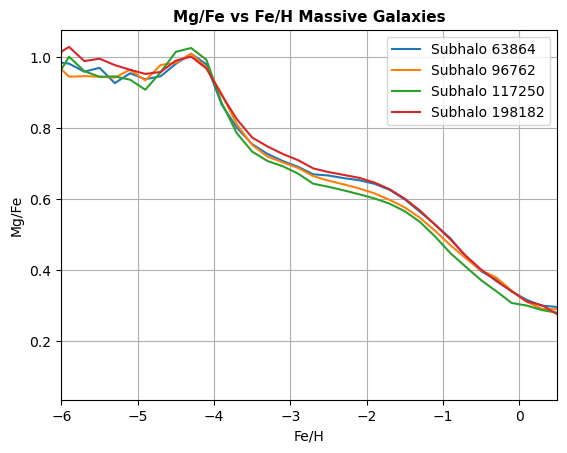

In [8]:
SubhaloIDsMassiveGalaxies = [ 63864, 96762, 117250, 198182] # [117269, 1] #Subhalo ID


for SubhaloIDs in SubhaloIDsMassiveGalaxies:
    subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])
    
    
    o = subhalo_stars['GFM_Metals'][:,4]
    fe = subhalo_stars['GFM_Metals'][:,8]
    mg = subhalo_stars['GFM_Metals'][:,6]
    h = subhalo_stars['GFM_Metals'][:,0]
    si = subhalo_stars['GFM_Metals'][:,7]
    ne = subhalo_stars['GFM_Metals'][:,5]
    
    
    mgfe =  np.log10( ( mg*56 ) / (fe*24) ) -0.09
    feh =  np.log10(fe/(h*56)) + 4.5
    
    
    #plt.scatter((feh),(mgfe), s = 0.7)
    plt.title('Mg/Fe vs Fe/H Massive Galaxies', fontsize=11, fontweight='bold')
    plt.xlim(-6,0.5)
    #plt.ylim(0,1.4)

    plt.ylabel('Mg/Fe')
    plt.xlabel('Fe/H')

    # Compute mean values in bins of 0.2 dex
    bin_width = 0.2
    bins = np.arange(-10, 5. + bin_width, bin_width)
    bin_means, bin_edges, _ = binned_statistic(feh, mgfe, statistic='mean', bins=bins)

    # Plot the mean values
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    plt.plot(bin_centers, bin_means,  label= f'Subhalo {SubhaloIDs}'  )
    plt.grid(True)
    plt.legend()
    # also load some metadata from this snapshot from the 'header'
    #header = il.groupcat.loadHeader(basePath_TNG50_4, snap)

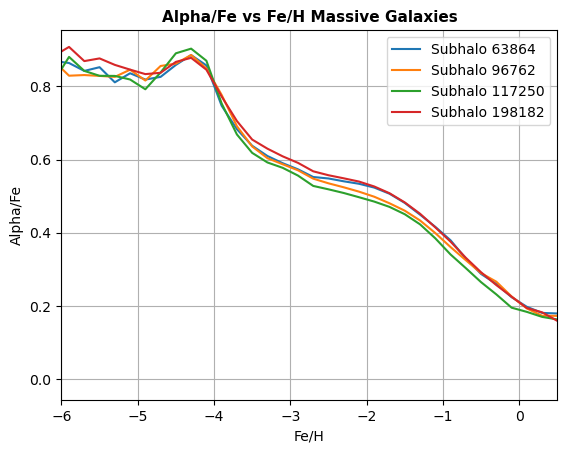

In [4]:
SubhaloIDs = [ 63864, 96762, 117250, 198182]        # [117269, 1] #Subhalo ID


for SubhaloIDs in SubhaloIDs:
    subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])
    
    
    o = subhalo_stars['GFM_Metals'][:,4]
    fe = subhalo_stars['GFM_Metals'][:,8]
    mg = subhalo_stars['GFM_Metals'][:,6]
    h = subhalo_stars['GFM_Metals'][:,0]
    si = subhalo_stars['GFM_Metals'][:,7]
    ne = subhalo_stars['GFM_Metals'][:,5]
    
    
    alphafe =  np.log10( ( 56 * (mg/24  + si/28 ) /2 ) / fe )   -0.09 - (7.51- 7.46)
    feh =  np.log10(fe/(h*56)) + 4.5
    
    
    #plt.scatter((feh),(mgfe), s = 0.7)
    plt.title('Alpha/Fe vs Fe/H Massive Galaxies', fontsize=11, fontweight='bold')
    plt.xlim(-6,0.5)
    #plt.ylim(0,1.4)

    plt.ylabel('Alpha/Fe')
    plt.xlabel('Fe/H')

    # Compute mean values in bins of 0.2 dex
    bin_width = 0.2
    bins = np.arange(-10, 5. + bin_width, bin_width)
    bin_means, bin_edges, _ = binned_statistic(feh, alphafe, statistic='mean', bins=bins)

    # Plot the mean values
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    plt.grid(True)
    plt.plot(bin_centers, bin_means,  label= f'Subhalo {SubhaloIDs}'  )
    
    plt.legend()
    # also load some metadata from this snapshot from the 'header'
    #header = il.groupcat.loadHeader(basePath_TNG50_4, snap)

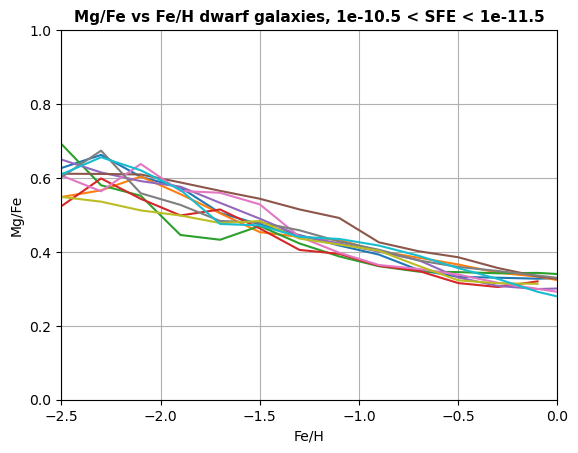

In [7]:
#SubhaloIDs = [ 88, 63908 , 117344 , 143938 ] 
SubhaloIDs = [69,
 81,
 88,
 137,
 63890,
 63905,
 63908,
 63909,
 63972,
 63976] 
# [117269, 1] #Subhalo ID


for SubhaloIDs in SubhaloIDs:
    subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])
    
    
    o = subhalo_stars['GFM_Metals'][:,4]
    fe = subhalo_stars['GFM_Metals'][:,8]
    mg = subhalo_stars['GFM_Metals'][:,6]
    h = subhalo_stars['GFM_Metals'][:,0]
    si = subhalo_stars['GFM_Metals'][:,7]
    ne = subhalo_stars['GFM_Metals'][:,5]
    
    
    mgfe =  np.log10( ((mg*56))/(fe*24)) -0.09
    feh =  np.log10(fe/(h*56)) + 4.5
    
    
    #plt.scatter((feh),(mgfe), s = 0.7)
    plt.title('Mg/Fe vs Fe/H dwarf galaxies, 1e-10.5 < SFE < 1e-11.5', fontsize=11, fontweight='bold')
    plt.xlim(-2.5,0)
    plt.ylim(0,1)

    plt.ylabel('Mg/Fe')
    plt.xlabel('Fe/H')

    # Compute mean values in bins of 0.2 dex
    bin_width = 0.2
    bins = np.arange(-10, 5. + bin_width, bin_width)
    bin_means, bin_edges, _ = binned_statistic(feh, mgfe, statistic='mean', bins=bins)

    # Plot the mean values
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    plt.grid(True)
    plt.plot(bin_centers, bin_means,  label= f'Subhalo {SubhaloIDs}'  )
    
    #plt.legend()
    # also load some metadata from this snapshot from the 'header'
    #header = il.groupcat.loadHeader(basePath_TNG50_4, snap)

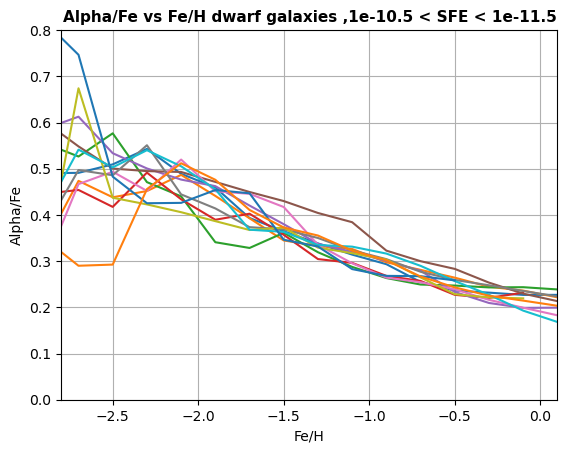

In [52]:
#SubhaloIDs = [ 88, 63908 , 117344 , 143938 ]           # [117269, 1] #Subhalo ID
SubhaloIDs = [69,
 81,
 88,
 137,
 63890,
 63905,
 63908,
 63909,
 63972,
 63976,
 63997,
 64190] 

for SubhaloIDs in SubhaloIDs:
    subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])
    
    
    o = subhalo_stars['GFM_Metals'][:,4]
    fe = subhalo_stars['GFM_Metals'][:,8]
    mg = subhalo_stars['GFM_Metals'][:,6]
    h = subhalo_stars['GFM_Metals'][:,0]
    si = subhalo_stars['GFM_Metals'][:,7]
    ne = subhalo_stars['GFM_Metals'][:,5]
    
    
    alphafe =  np.log10( ( 56 * (mg/24 + si/28)/2 )/ fe )   -0.09 - (7.51- 7.46)
    feh =  np.log10(fe/(h*56)) + 4.5
    
    
    #plt.scatter((feh),(mgfe), s = 0.7)
    plt.title('Alpha/Fe vs Fe/H dwarf galaxies ,1e-10.5 < SFE < 1e-11.5', fontsize=11, fontweight='bold')
    plt.xlim(-2.8,0.1)
    plt.ylim(0,0.8)

    plt.ylabel('Alpha/Fe')
    plt.xlabel('Fe/H')

    # Compute mean values in bins of 0.5 dex
    bin_width = 0.2
    bins = np.arange(-10, 5. + bin_width, bin_width)
    bin_means, bin_edges, _ = binned_statistic(feh, alphafe, statistic='mean', bins=bins)

    # Plot the mean values
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    plt.grid(True)
    plt.plot(bin_centers, bin_means,  label= f'Subhalo {SubhaloIDs}'  )
    
    #plt.legend()
    # also load some metadata from this snapshot from the 'header'
    #header = il.groupcat.loadHeader(basePath_TNG50_4, snap)

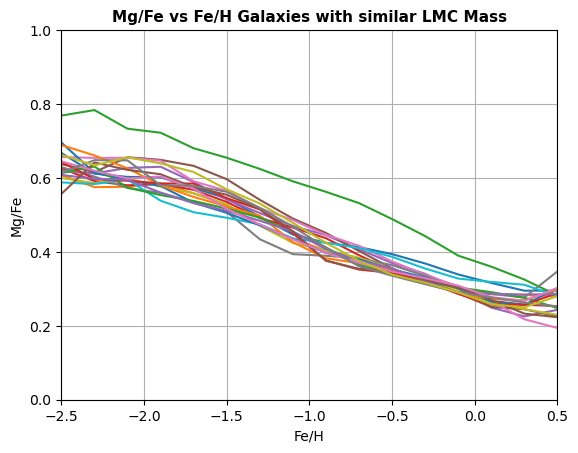

In [19]:
SubhaloIDs = [80,
 198189,
 208842,
 229946,
 348908,
 422760,
 432110,
 616627,
 674459,
 675743,
 678504,
 679408,
 681477,
 685549,
 686043,
 692471,
 699398,
 703083,
 703372] # [117269, 1] #Subhalo ID


for SubhaloIDs in SubhaloIDs:
    subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])
    
    
    o = subhalo_stars['GFM_Metals'][:,4]
    fe = subhalo_stars['GFM_Metals'][:,8]
    mg = subhalo_stars['GFM_Metals'][:,6]
    h = subhalo_stars['GFM_Metals'][:,0]
    si = subhalo_stars['GFM_Metals'][:,7]
    ne = subhalo_stars['GFM_Metals'][:,5]
    
    
    mgfe =  np.log10( ((mg*56))/(fe*24)) -0.09
    feh =  np.log10(fe/(h*56)) + 4.5
    
    #plt.scatter((feh),(mgfe), s = 0.7)
    plt.title('Mg/Fe vs Fe/H Galaxies with similar LMC Mass', fontsize=11, fontweight='bold')
    plt.xlim(-2.5,0.5)
    plt.ylim(0,1)

    plt.ylabel('Mg/Fe')
    plt.xlabel('Fe/H')

    # Compute mean values in bins of 0.5 dex
    bin_width = 0.2
    bins = np.arange(-10, 5. + bin_width, bin_width)
    bin_means, bin_edges, _ = binned_statistic(feh, mgfe, statistic='mean', bins=bins)

    # Plot the mean values
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    plt.grid(True)
    plt.plot(bin_centers, bin_means,  label= f'Subhalo {SubhaloIDs}'  )
    
    #plt.legend()
    # also load some metadata from this snapshot from the 'header'
    #header = il.groupcat.loadHeader(basePath_TNG50_4, snap)

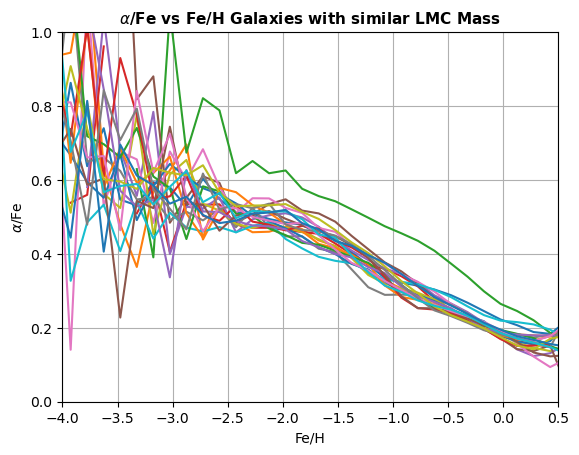

In [53]:
SubhaloIDsSimilarLMCMass = [80,
 198189,
 208842,
 229946,
 348908,
 422760,
 432110,
 616627,
 674459,
 675743,
 678504,
 679408,
 681477,
 685549,
 686043,
 692471,
 699398,
 703083,
 703372,
 704247,
 793245] # [117269, 1] #Subhalo ID

values_x_at_y_0_4 = []
for SubhaloIDs in SubhaloIDsSimilarLMCMass:
    subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])
    
    
    fe = subhalo_stars['GFM_Metals'][:,8]
    mg = subhalo_stars['GFM_Metals'][:,6]
    h = subhalo_stars['GFM_Metals'][:,0]
    si = subhalo_stars['GFM_Metals'][:,7]
    
    
    alphafe =  np.log10( ( 56 * (mg/24 + si/28)/2 )/ fe )   -0.09 - (7.51- 7.46)
    feh =  np.log10(fe/(h*56)) + 4.5
    
    
    #plt.scatter((feh),(mgfe), s = 0.7)
    plt.title(r'$\alpha$/Fe vs Fe/H Galaxies with similar LMC Mass', fontsize=11, fontweight='bold')
    plt.xlim(-4,0.5)
    plt.ylim(0,1)

    plt.ylabel(r'$\alpha$/Fe')
    plt.xlabel('Fe/H')

    # Compute mean values in bins of 0.5 dex
    bin_width = 0.15
    bins = np.arange(-10, 5. + bin_width, bin_width)
    bin_means, bin_edges, _ = binned_statistic(feh, alphafe, statistic='mean', bins=bins)

    # Plot the mean values
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    plt.grid(True)
    plt.plot(bin_centers, bin_means,  label= f'Subhalo {SubhaloIDs}'  )
      
   
    
    #plt.legend()
    # also load some metadata from this snapshot from the 'header'
    #header = il.groupcat.loadHeader(basePath_TNG50_4, snap)

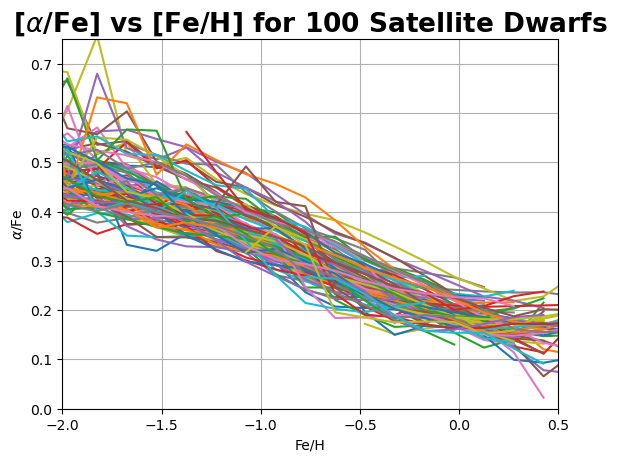

In [122]:
SubhaloIDsSatelliteDwarfs = idsSatelliteDwarfs[0:100] # [117269, 1] #Subhalo ID

for SubhaloIDs in SubhaloIDsSatelliteDwarfs:
    subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])
    
    
    fe = subhalo_stars['GFM_Metals'][:,8]
    mg = subhalo_stars['GFM_Metals'][:,6]
    h = subhalo_stars['GFM_Metals'][:,0]
    si = subhalo_stars['GFM_Metals'][:,7]
    
    
    alphafe =  np.log10( ( 56 * (mg/24 + si/28)/2 )/ fe )   -0.09 - (7.51- 7.46)
    feh =  np.log10(fe/(h*56)) + 4.5
    
    
    #plt.scatter((feh),(mgfe), s = 0.7)
    plt.title(r'[$\alpha$/Fe] vs [Fe/H] for 100 Satellite Dwarfs', fontsize=19, fontweight='bold')
    plt.xlim(-2,0.5)
    plt.ylim(0,0.75)

    plt.ylabel(r'$\alpha$/Fe')
    plt.xlabel('Fe/H')

    # Compute mean values in bins of 0.5 dex
    bin_width = 0.15
    bins = np.arange(-10, 5. + bin_width, bin_width)
    bin_means, bin_edges, _ = binned_statistic(feh, alphafe, statistic='mean', bins=bins)

    # Plot the mean values
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    plt.grid(True)
    plt.plot(bin_centers, bin_means,  label= f'Subhalo {SubhaloIDs}'  )
      
   
    
    #plt.legend()
    # also load some metadata from this snapshot from the 'header'
    #header = il.groupcat.loadHeader(basePath_TNG50_4, snap)
    
plt.savefig('/home/tnguser/Lucas/images/TNG50-1_SatelliteDwarfs')

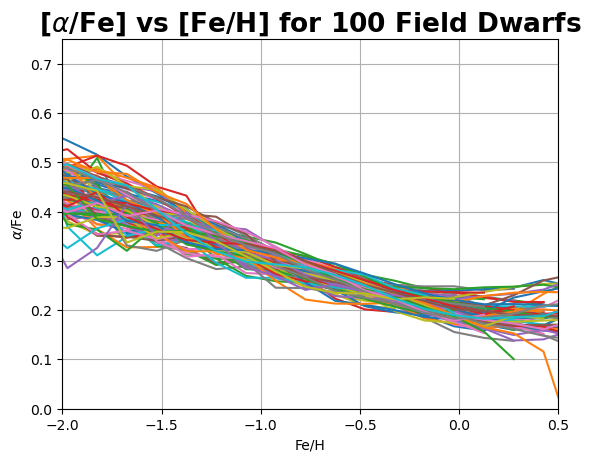

In [123]:
SubhaloIDsFieldDwarfs = idsFieldDwarfs[0:100] # [117269, 1] #Subhalo ID


for SubhaloIDs in SubhaloIDsFieldDwarfs:
    subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])
    
    
    fe = subhalo_stars['GFM_Metals'][:,8]
    mg = subhalo_stars['GFM_Metals'][:,6]
    h = subhalo_stars['GFM_Metals'][:,0]
    si = subhalo_stars['GFM_Metals'][:,7]
    
    
    alphafe =  np.log10( ( 56 * (mg/24 + si/28)/2 )/ fe )   -0.09 - (7.51- 7.46)
    feh =  np.log10(fe/(h*56)) + 4.5
    
    
    #plt.scatter((feh),(mgfe), s = 0.7)
    plt.title(r'[$\alpha$/Fe] vs [Fe/H] for 100 Field Dwarfs', fontsize=19, fontweight='bold')
    plt.xlim(-2,0.5)
    plt.ylim(0,0.75)

    plt.ylabel(r'$\alpha$/Fe')
    plt.xlabel('Fe/H')

    # Compute mean values in bins of 0.5 dex
    bin_width = 0.15
    bins = np.arange(-10, 5. + bin_width, bin_width)
    bin_means, bin_edges, _ = binned_statistic(feh, alphafe, statistic='mean', bins=bins)

    # Plot the mean values
    bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])
    plt.grid(True)
    plt.plot(bin_centers, bin_means,  label= f'Subhalo {SubhaloIDs}'  )
      
   
    
    #plt.legend()
    # also load some metadata from this snapshot from the 'header'
    #header = il.groupcat.loadHeader(basePath_TNG50_4, snap)
    

plt.savefig('/home/tnguser/Lucas/images/TNG50-1_FieldDwarfs')

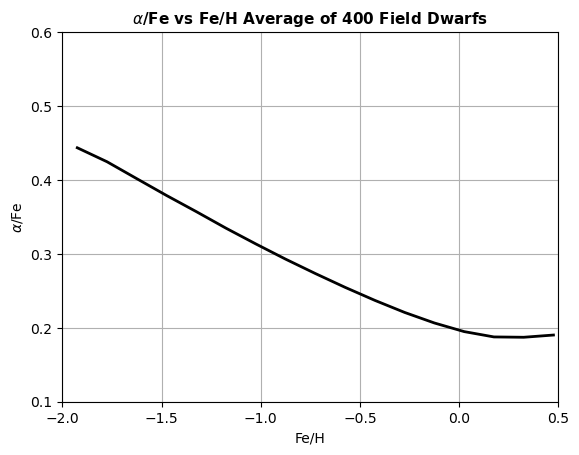

<Figure size 640x480 with 0 Axes>

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

SubhaloIDsFieldDwarfs = idsFieldDwarfs[0:400] 
all_bin_means = [] 

bin_width = 0.15
bins = np.arange(-2, 0.5 + bin_width, bin_width)  
bin_centersfield = 0.5 * (bins[1:] + bins[:-1])  

for SubhaloIDs in SubhaloIDsFieldDwarfs:
    subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])
    
    fe = subhalo_stars['GFM_Metals'][:,8]
    mg = subhalo_stars['GFM_Metals'][:,6]
    h = subhalo_stars['GFM_Metals'][:,0]
    si = subhalo_stars['GFM_Metals'][:,7]
    
    alphafe =  np.log10((56 * (mg/24 + si/28)/2) / fe) - 0.09 - (7.51 - 7.46)
    feh =  np.log10(fe/(h*56)) + 4.5

    #mean values in bins
    bin_means, _, _ = binned_statistic(feh, alphafe, statistic='mean', bins=bins)
    all_bin_means.append(bin_means)
    
    #plt.plot(bin_centers, bin_means, alpha=0.5, label=f'Subhalo {SubhaloIDs}')

#Compute the median line
all_bin_meansfield = np.array(all_bin_means)
median_bin_meansfield = np.nanmean(all_bin_means, axis=0)

#Plot the median line
plt.plot(bin_centersfield, median_bin_meansfield, color='black', linewidth=2, label='Median Line')

plt.title(r'$\alpha$/Fe vs Fe/H Average of 400 Field Dwarfs', fontsize=11, fontweight='bold')
plt.xlim(-2, 0.5)
plt.ylim(0.1, 0.6)
plt.ylabel(r'$\alpha$/Fe')
plt.xlabel('Fe/H')
plt.grid(True)
#plt.legend()
plt.show()
plt.savefig('/home/tnguser/Lucas/images/TNG50-1_AVGFieldDwarfs')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

# Assuming `il` and required inputs are already defined
SubhaloIDsSatelliteDwarfs = idsSatelliteDwarfs[0:400] # Subhalo IDs
all_bin_means = []  # To store all bin mean arrays

bin_width = 0.15
bins = np.arange(-2, 0.5 + bin_width, bin_width)  # Adjust bin range as needed
bin_centers = 0.5 * (bins[1:] + bins[:-1])  # Centers of the bins

for SubhaloIDs in SubhaloIDsSatelliteDwarfs:
    subhalo_stars = il.snapshot.loadSubhalo(basePath_TNG50, snap, SubhaloIDs, 'stars', fields=['GFM_Metals','Masses'])
    
    fe = subhalo_stars['GFM_Metals'][:,8]
    mg = subhalo_stars['GFM_Metals'][:,6]
    h = subhalo_stars['GFM_Metals'][:,0]
    si = subhalo_stars['GFM_Metals'][:,7]
    
    alphafe =  np.log10((56 * (mg/24 + si/28)/2) / fe) - 0.09 - (7.51 - 7.46)
    feh =  np.log10(fe/(h*56)) + 4.5

    #mean values
    bin_means, _, _ = binned_statistic(feh, alphafe, statistic='mean', bins=bins)
    all_bin_means.append(bin_means)
    
    #plt.plot(bin_centers, bin_means, alpha=0.5, label=f'Subhalo {SubhaloIDs}')

#Compute the median line
all_bin_means = np.array(all_bin_means)
median_bin_means = np.nanmean(all_bin_means, axis=0)

#Plot the median line
plt.plot(bin_centers, median_bin_means, color='black', linewidth=2, label='Median Line')

plt.title(r'$\alpha$/Fe vs Fe/H Average of 400 Satellite Dwarfs', fontsize=11, fontweight='bold')
plt.xlim(-2, 0.5)
plt.ylim(0.1, 0.6)
plt.ylabel(r'$\alpha$/Fe')
plt.xlabel('Fe/H')
plt.grid(True)
#plt.legend()
plt.show()
plt.savefig('/home/tnguser/Lucas/images/TNG50-1_AVGSatelliteDwarfs')

Text(0.5, 1.0, 'Average of 800 Dwarf Galaxies')

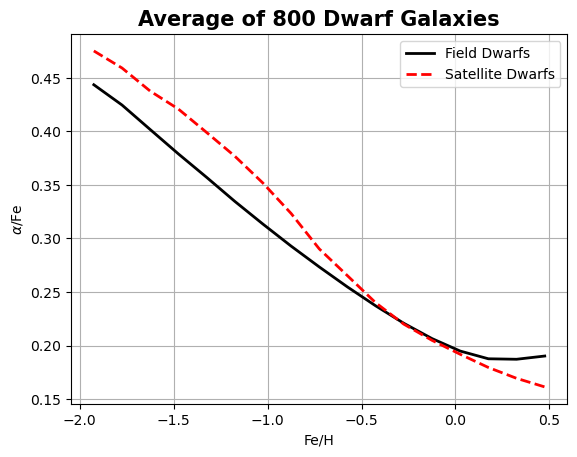

In [115]:
plt.plot(bin_centersfield, median_bin_meansfield, color='k', linewidth=2, label='Field Dwarfs')
plt.plot(bin_centers, median_bin_means, color='red', linestyle = '--', linewidth=2, label='Satellite Dwarfs')
plt.legend()
plt.grid(True)
plt.ylabel(r'$\alpha$/Fe')
plt.xlabel('Fe/H')
plt.title('Average of 800 Dwarf Galaxies',fontsize=15, fontweight='bold')